# Improve KumoRelational performance on imbalanced data

KumoRelational, a relational foundation model (RFM), predicts from labeled in-context examples. This notebook demonstrates three strategies for imbalanced data plus sampling settings, and measures the lift of each, using an imbalanced classes fraud detection use case as the example: which accounts will be confirmed as fraud within 30 days?

| Strategy | Targets | What changes |
| --- | --- | --- |
| 1. Rebalance the context | Class imbalance | Include all positives; test class ratios, context size and positive repetition. |
| 2. Ensemble contexts | Class imbalance | Keep the positives fixed, vary the negatives, average the predictions. |
| 3. Tune sampling | Any dataset | Recent entities, most recent neighbors, neighbor count. |
| 4. Tune the threshold | Class imbalance | Pick a cutoff on validation data for each configuration. |

Sampling is not an imbalance strategy and can help a balanced dataset as much, so the lift summary reports it separately.

Runs locally with Python 3.12 or later (tested on 3.13) and [direct KumoRelational](https://nvidia.github.io/structured-data-models/api/generated/sdm.models.KumoRelational.html). A GPU is recommended. Data is synthetic; metrics are **demonstration only**.

## Install and configure

Sampling runs on CPU even when the model uses a GPU, so it always needs a [pyg-lib wheel](https://pytorch-geometric.readthedocs.io/en/latest/install/installation.html) matching your PyTorch version; the schema diagram needs [Graphviz](https://graphviz.org/download/). See [installation](https://nvidia.github.io/structured-data-models/install.html).

In [1]:
%pip install structured-data-models pandas pyarrow scikit-learn matplotlib graphviz

## Set the parameters

Accounts are split by observation date into a context pool, a validation window for choosing settings and thresholds, and a test window for reporting.

In [2]:
SEED = 7
N_ACCOUNTS = 100_000
FRAUD_RATE = 0.007
START = "2026-01-01"
HISTORY_DAYS = 90
HORIZON_DAYS = 30
VALIDATION_START_DAY = 250
TEST_START_DAY = 310

BASELINE_CONTEXT_SIZE = 5_000
LARGE_CONTEXT_SIZE = 10_000
FRAUD_REPEAT = 10
NUM_ESTIMATORS = 5
RECENT_CONTEXT_DAYS = 90
FIRST_HOP_NEIGHBORS = 8
SECOND_HOP_NEIGHBORS = 4
NEIGHBOR_OPTIONS = [16]

DEFAULT_THRESHOLD = 0.5
TARGET_PRECISION = 0.5
OUTPUT_PARENT = None
CLEANUP = False

Import the libraries and create an output directory for this run.

In [3]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sdm
import torch
from IPython.display import display
from sklearn.metrics import average_precision_score, f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
rng = np.random.default_rng(SEED)
workspace = tempfile.TemporaryDirectory(prefix="fraud-context-tuning-", dir=OUTPUT_PARENT, delete=False)
run_dir = Path(workspace.name)
print("Device:", device, "| Results:", run_dir)

## Generate synthetic example data

Run the next cell to create five tables: customers, accounts, transactions, merchants and devices. You can skim it; the workflow starts at **Build the relational data**.

Fraud accounts tend to show a burst of activity just before their observation date, often at high-risk merchants or on shared or emulated devices, and belong to newer customers. Some legitimate accounts look similar, and the fraud pattern drifts in early May. Accounts carry an open date and customers a join date, so the sampler can exclude records created after each observation date.

In [4]:
N_CUSTOMERS = int(N_ACCOUNTS * 0.75)
N_MERCHANTS = 2_000
N_SHARED_DEVICES = 1_500
DRIFT_DAY = 120

merchants = pd.DataFrame({
    "merchant_id": np.arange(N_MERCHANTS),
    "risk_score": rng.beta(1.5, 12, N_MERCHANTS).round(3),
    "is_online": (rng.random(N_MERCHANTS) < 0.4).astype(float),
    "avg_ticket": rng.lognormal(3.6, 0.6, N_MERCHANTS).round(2),
})
risky_merchants = {
    "early": merchants.merchant_id[(merchants.risk_score > merchants.risk_score.quantile(0.9)) & (merchants.is_online == 0)].to_numpy(),
    "late": merchants.merchant_id[(merchants.risk_score > merchants.risk_score.quantile(0.9)) & (merchants.is_online == 1)].to_numpy(),
}
everyday_merchants = merchants.merchant_id[merchants.risk_score <= merchants.risk_score.quantile(0.9)].to_numpy()

customers = pd.DataFrame({
    "customer_id": np.arange(N_CUSTOMERS),
    "customer_age_years": rng.integers(18, 85, N_CUSTOMERS).astype(float),
    "joined_at": pd.Timestamp(START) - pd.to_timedelta(rng.gamma(3.0, 400, N_CUSTOMERS).round(), unit="D"),
    "kyc_tier": rng.integers(1, 4, N_CUSTOMERS).astype(float),
})
devices = pd.DataFrame({
    "device_id": np.arange(N_CUSTOMERS + N_SHARED_DEVICES),
    "is_emulator": np.r_[np.zeros(N_CUSTOMERS), (rng.random(N_SHARED_DEVICES) < 0.7)].astype(float),
})
recent_customers = customers.customer_id[customers.joined_at > pd.Timestamp(START) - pd.Timedelta(days=180)].to_numpy()
shared_devices = np.arange(N_CUSTOMERS, N_CUSTOMERS + N_SHARED_DEVICES)


def simulate_transactions(owners, anchors, owner_devices, window_days, pattern):
    n = len(owners)
    if pattern == "everyday":
        amount, intl, hour, merchant = rng.lognormal(3.5, 0.9, n), rng.random(n) < 0.05, rng.normal(14, 4, n), rng.choice(everyday_merchants, n)
        device = np.where(rng.random(n) < 0.02, rng.choice(shared_devices, n), owner_devices)
    elif pattern == "lookalike":
        amount = np.where(rng.random(n) < 0.5, rng.lognormal(3.0, 0.6, n), rng.lognormal(5.8, 0.6, n))
        intl, hour = rng.random(n) < 0.5, np.where(rng.random(n) < 0.5, rng.normal(2, 2, n), rng.normal(14, 4, n))
        merchant = np.where(rng.random(n) < 0.3, rng.choice(np.r_[risky_merchants["early"], risky_merchants["late"]], n), rng.choice(everyday_merchants, n))
        device = np.where(rng.random(n) < 0.25, rng.choice(shared_devices, n), owner_devices)
    else:
        late = pattern == "late"
        amount = rng.lognormal(3.0, 0.6, n) if late else rng.lognormal(6.0, 0.6, n)
        intl, hour = rng.random(n) < (0.6 if late else 0.15), rng.normal(2, 2, n) if late else rng.normal(14, 4, n)
        merchant = np.where(rng.random(n) < 0.35, rng.choice(risky_merchants[pattern], n), rng.choice(everyday_merchants, n))
        device = np.where(rng.random(n) < (0.35 if late else 0.1), rng.choice(shared_devices, n), owner_devices)
    return pd.DataFrame({
        "account_id": owners, "merchant_id": merchant, "device_id": device,
        "timestamp": anchors - pd.to_timedelta(rng.uniform(0, window_days, n), unit="D"),
        "amount": amount.round(2), "is_international": intl.astype(float), "hour_of_day": hour.clip(0, 23).round(),
    })


def simulate_accounts(account_ids, anchors):
    n = len(account_ids)
    is_fraud = rng.random(n) < FRAUD_RATE
    owner = np.where(is_fraud & (rng.random(n) < 0.4), rng.choice(recent_customers, n), rng.integers(0, N_CUSTOMERS, n))
    late = (anchors - pd.Timestamp(START)).days.to_numpy() >= DRIFT_DAY
    account_frame = pd.DataFrame({
        "account_id": account_ids, "customer_id": owner,
        "opened_at": np.maximum(
            anchors - pd.to_timedelta(np.where(is_fraud, rng.gamma(2.0, 150, n), rng.gamma(3.0, 300, n)).round() + HISTORY_DAYS, unit="D"),
            customers.joined_at.to_numpy()[owner] + pd.Timedelta(days=1),
        ),
        "credit_limit": rng.lognormal(8.0, 0.6, n).round(-2),
    })
    counts = rng.poisson(24, n) + 4
    parts = [simulate_transactions(np.repeat(account_ids, counts), np.repeat(anchors.values, counts), np.repeat(owner, counts), HISTORY_DAYS, "everyday")]
    bursty_fraud = is_fraud & (rng.random(n) < 0.8)
    lookalikes = ~is_fraud & (rng.random(n) < 0.04)
    for selected, mean_count, pattern in (
        (bursty_fraud & ~late, 4, "early"), (bursty_fraud & late, 4, "late"), (lookalikes, 4, "lookalike"),
    ):
        k = rng.poisson(mean_count, selected.sum()) + 1
        parts.append(simulate_transactions(
            np.repeat(account_ids[selected], k), np.repeat(anchors.values[selected], k), np.repeat(owner[selected], k), 5, pattern
        ))
    transaction_frame = pd.concat(parts, ignore_index=True).sort_values("timestamp", ignore_index=True)
    transaction_frame["timestamp"] = transaction_frame.timestamp.dt.floor("s")
    label_frame = pd.DataFrame({"account_id": account_ids, "timestamp": anchors, "is_fraud": np.where(is_fraud, "fraud", "legit")})
    return account_frame, transaction_frame, label_frame


history_anchors = pd.Timestamp(START) + pd.to_timedelta(rng.integers(60, 365, N_ACCOUNTS), unit="D")
accounts, transactions, labels = simulate_accounts(np.arange(N_ACCOUNTS), history_anchors)
transactions.insert(0, "transaction_id", np.arange(len(transactions)))

display(pd.Series({"customers": len(customers), "accounts": len(accounts), "transactions": len(transactions),
                   "merchants": len(merchants), "devices": len(devices)}, name="rows").to_frame())
print(f"Fraud rate: {labels.is_fraud.eq('fraud').mean():.2%} (about 1 in {round(1 / labels.is_fraud.eq('fraud').mean())})")

,rows
customers,75000
accounts,100000
transactions,2821422
merchants,2000
devices,76500


Fraud rate: 0.69% (about 1 in 145)


## Build the relational data

Declare column types and foreign keys. KumoRelational uses numerical and datetime features. The sampler only uses transactions, accounts and customers dated before each observation date, so another account of the same customer opened later is excluded; merchant and device attributes are static. See [RelationalData](https://nvidia.github.io/structured-data-models/api/generated/sdm.relational.RelationalData.html).

In [5]:
STYPES = {
    "customers": {"customer_id": "id", "customer_age_years": "numerical", "joined_at": "datetime", "kyc_tier": "numerical"},
    "accounts": {"account_id": "id", "customer_id": "id", "opened_at": "datetime", "credit_limit": "numerical"},
    "merchants": {"merchant_id": "id", "risk_score": "numerical", "is_online": "numerical", "avg_ticket": "numerical"},
    "devices": {"device_id": "id", "is_emulator": "numerical"},
    "transactions": {
        "transaction_id": "id", "account_id": "id", "merchant_id": "id", "device_id": "id", "timestamp": "datetime",
        "amount": "numerical", "is_international": "numerical", "hour_of_day": "numerical",
    },
}
RELATIONSHIPS = [
    {"left_table": "accounts", "left_column": "customer_id", "right_table": "customers", "right_column": "customer_id"},
    {"left_table": "transactions", "left_column": "account_id", "right_table": "accounts", "right_column": "account_id"},
    {"left_table": "transactions", "left_column": "merchant_id", "right_table": "merchants", "right_column": "merchant_id"},
    {"left_table": "transactions", "left_column": "device_id", "right_table": "devices", "right_column": "device_id"},
]
TASK_LINK = {"task_column": "account_id", "table": "accounts", "table_column": "account_id"}

frames = {"customers": customers, "accounts": accounts, "merchants": merchants, "devices": devices, "transactions": transactions}
data = sdm.RelationalData(
    tables={name: sdm.TableTensor.from_pandas(frame, stypes=STYPES[name]) for name, frame in frames.items()},
    relationships=RELATIONSHIPS,
)
sampler = data.sampler(time_columns={"transactions": "timestamp", "accounts": "opened_at", "customers": "joined_at"})
task_table = sdm.TableTensor.from_pandas(labels, stypes={"account_id": "id", "timestamp": "datetime", "is_fraud": "categorical"})

Merchant and device risk sit two hops from an account, through its transactions.

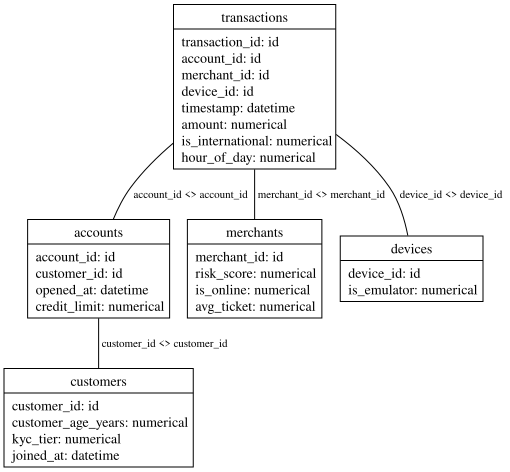

In [6]:
data.to_graphviz()

## Split accounts by time

Each label needs 30 days to mature, so each window ends 30 days before the next one starts: context pool before day 220, validation days 250 to 279, test from day 310. Settings are then fixed using only outcomes known before the windows they are applied to.

In [7]:
observation_day = (labels.timestamp - pd.Timestamp(START)).dt.days.to_numpy()
is_fraud = labels.is_fraud.eq("fraud").to_numpy()
pool_rows = np.flatnonzero(observation_day < VALIDATION_START_DAY - HORIZON_DAYS)
val_rows = np.flatnonzero((observation_day >= VALIDATION_START_DAY) & (observation_day < TEST_START_DAY - HORIZON_DAYS))
test_rows = np.flatnonzero(observation_day >= TEST_START_DAY)
fraud_pool = pool_rows[is_fraud[pool_rows]]
legit_pool = pool_rows[~is_fraud[pool_rows]]
y_val, y_test = is_fraud[val_rows], is_fraud[test_rows]

display(pd.DataFrame({
    "accounts": [len(pool_rows), len(val_rows), len(test_rows)],
    "fraud_accounts": [is_fraud[pool_rows].sum(), y_val.sum(), y_test.sum()],
}, index=["context pool", "validation", "test"]))

,accounts,fraud_accounts
context pool,52458,352
validation,9814,67
test,18022,124


## Define the helpers

`score_contexts` fits the model on each context, scores the queries and averages the probabilities; `score_validation` scores only validation accounts for tuning trials; one context is an ensemble of one. Sampling covers two hops: `num_neighbors` transactions per account, then each transaction's merchant and device, plus up to `SECOND_HOP_NEIGHBORS` accounts per customer. See [RelationalSampler](https://nvidia.github.io/structured-data-models/api/generated/sdm.relational.RelationalSampler.html).

In [8]:
model = sdm.models.KumoRelational(device=device)
evaluation_query = task_table[torch.as_tensor(np.concatenate([val_rows, test_rows]))].drop_columns("is_fraud")


def score_contexts(contexts, query, relational_sampler, num_neighbors=FIRST_HOP_NEIGHBORS, temporal_strategy="uniform", batch_size=10_000):
    options = dict(task_link=TASK_LINK, num_neighbors=[num_neighbors, SECOND_HOP_NEIGHBORS], task_time_column="timestamp", temporal_strategy=temporal_strategy)
    member_probabilities = []
    for context_rows in contexts:
        torch.manual_seed(SEED)
        context, related = relational_sampler(task_table[torch.as_tensor(context_rows)], **options).to(device)
        model.fit(x=context.drop_columns("is_fraud"), y=context["is_fraud"], related_tables=related)
        batches = []
        for query_batch in query.split(batch_size, -2):
            out = model.predict(*relational_sampler(query_batch, **options).to(device))
            batches.append(out.numerical[:, list(out.columns[sdm.Stype.numerical]).index("fraud")].float().cpu().numpy())
        member_probabilities.append(np.concatenate(batches))
    return np.mean(member_probabilities, axis=0)


def score_evaluation(contexts, **options):
    probabilities = score_contexts(contexts, evaluation_query, sampler, **options)
    return probabilities[: len(val_rows)], probabilities[len(val_rows):]


def score_validation(contexts, **options):
    return score_contexts(contexts, evaluation_query[: len(val_rows)], sampler, **options)


def metrics(y_true, probability, threshold):
    flagged = probability >= threshold
    return {
        "average_precision": average_precision_score(y_true, probability),
        "auroc": roc_auc_score(y_true, probability),
        "precision": precision_score(y_true, flagged, zero_division=0),
        "recall": recall_score(y_true, flagged),
        "f1": f1_score(y_true, flagged),
        "threshold": threshold,
    }


def max_f1_threshold(y_true, probability):
    precision, recall, thresholds = precision_recall_curve(y_true, probability)
    f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    return thresholds[np.argmax(f1)]


def compose_context(fraud_rows, legit_rows, n_legit, fraud_repeat=1):
    return np.concatenate([np.tile(fraud_rows, fraud_repeat), rng.choice(legit_rows, n_legit, replace=False)])


stages = {}

## Score the baseline

Use a random context at the natural fraud rate and the default 0.5 cutoff.

In [9]:
baseline_context = rng.choice(pool_rows, BASELINE_CONTEXT_SIZE, replace=False)
baseline_val, baseline_test = score_evaluation([baseline_context])
stages["Baseline"] = (baseline_val, baseline_test)
print(f"Fraud examples in the baseline context: {is_fraud[baseline_context].sum()} of {BASELINE_CONTEXT_SIZE}")
display(pd.DataFrame({"Baseline": metrics(y_test, baseline_test, DEFAULT_THRESHOLD)}).T.round(3))

Fraud examples in the baseline context: 44 of 5000


,average_precision,auroc,precision,recall,f1,threshold
Baseline,0.239,0.908,0.818,0.073,0.133,0.5


With few positives in context, the model is conservative: reasonable precision, low recall.

## Strategy 1: rebalance the context

Every candidate contains all fraud accounts in the pool: ratios of 1:1, 1:5 and 1:20, a 10,000-row context, and a 10,000-row context with each fraud account repeated 10 times. Select by validation average precision, which is threshold-free.

In [10]:
n_fraud = len(fraud_pool)
if FRAUD_REPEAT * n_fraud >= LARGE_CONTEXT_SIZE:
    raise ValueError(f"FRAUD_REPEAT={FRAUD_REPEAT} needs {FRAUD_REPEAT * n_fraud:,} fraud rows, more than LARGE_CONTEXT_SIZE={LARGE_CONTEXT_SIZE:,}.")
context_designs = {
    "1:1": (1, n_fraud),
    "1:5": (1, 5 * n_fraud),
    "1:20": (1, 20 * n_fraud),
    f"All fraud, {LARGE_CONTEXT_SIZE:,} rows": (1, LARGE_CONTEXT_SIZE - n_fraud),
    f"Fraud x{FRAUD_REPEAT}, {LARGE_CONTEXT_SIZE:,} rows": (FRAUD_REPEAT, LARGE_CONTEXT_SIZE - FRAUD_REPEAT * n_fraud),
}
design_scores = {}
for name, (fraud_repeat, n_legit) in context_designs.items():
    design_val, design_test = score_evaluation([compose_context(fraud_pool, legit_pool, n_legit, fraud_repeat)])
    design_scores[name] = (design_val, design_test)

comparison = pd.DataFrame({
    name: {
        "validation_average_precision": average_precision_score(y_val, design_val),
        "validation_recall_at_0.5": recall_score(y_val, design_val >= DEFAULT_THRESHOLD),
        "validation_precision_at_0.5": precision_score(y_val, design_val >= DEFAULT_THRESHOLD, zero_division=0),
    }
    for name, (design_val, _) in design_scores.items()
}).T
best_design = comparison.validation_average_precision.idxmax()
fraud_repeat, n_legit = context_designs[best_design]
stages["+ Rebalanced context"] = design_scores[best_design]
display(comparison.round(3))
print("Selected context design:", best_design)

,validation_average_precision,validation_recall_at_0.5,validation_precision_at_0.5
1:1,0.377,0.896,0.048
1:5,0.362,0.761,0.079
1:20,0.405,0.478,0.296
"All fraud, 10,000 rows",0.394,0.463,0.307
"Fraud x10, 10,000 rows",0.243,0.418,0.167


Selected context design: 1:20


Fewer negatives per positive also raise the probabilities, which moves precision and recall at 0.5; strategy 4 handles this.

## Strategy 2: ensemble contexts

Use the same fraud accounts in every context with a different draw of negatives, then average the members. See [ensembling](https://nvidia.github.io/structured-data-models/icl.html).

In [11]:
ensemble_contexts = [compose_context(fraud_pool, legit_pool, n_legit, fraud_repeat) for _ in range(NUM_ESTIMATORS)]
member_scores = [score_evaluation([context]) for context in ensemble_contexts]
member_val_ap = [average_precision_score(y_val, member_val) for member_val, _ in member_scores]
ensemble_val = np.mean([member_val for member_val, _ in member_scores], axis=0)
ensemble_test = np.mean([member_test for _, member_test in member_scores], axis=0)
stages["+ Context ensemble"] = (ensemble_val, ensemble_test)
print("Validation AP per member:", np.round(member_val_ap, 3))
print(f"Validation AP of the ensemble: {average_precision_score(y_val, ensemble_val):.3f}")

Validation AP per member: [0.363 0.403 0.4   0.384 0.388]
Validation AP of the ensemble: 0.423


The ensemble mainly reduces variance from the negative draw; it beats the average member, but not always the best one.

## Strategy 3: tune sampling

These settings change how neighbors are sampled, not how the rare class is represented, so they apply to any dataset. Test each change on the first ensemble member's context rows, so only the sampling setting changes, and keep it only if validation average precision improves:

* **Recent accounts:** build the context from the pool's last 90 days at the same class ratio. That window holds fewer positives, so this trial changes context size too. Draw both classes from that window, or the observation date leaks the label.
* **Most recent transactions:** `temporal_strategy="last"` instead of a uniform sample.
* **More neighbors:** more first-hop transactions per account.

In [12]:
recent_rows = pool_rows[observation_day[pool_rows] >= VALIDATION_START_DAY - RECENT_CONTEXT_DAYS]
recent_fraud, recent_legit = recent_rows[is_fraud[recent_rows]], recent_rows[~is_fraud[recent_rows]]
legit_per_fraud = n_legit / n_fraud


def recent_context():
    return compose_context(recent_fraud, recent_legit, round(legit_per_fraud * len(recent_fraud)), fraud_repeat)


trial_contexts = {False: ensemble_contexts[0], True: recent_context()}
trials = []


def record(change, use_recent, num_neighbors, temporal_strategy, val_prob):
    context = trial_contexts[use_recent]
    trials.append({"change": change, "context_rows": len(context), "fraud_rows": int(is_fraud[context].sum()),
                   "num_neighbors": num_neighbors, "temporal_strategy": temporal_strategy,
                   "validation_average_precision": average_precision_score(y_val, val_prob)})
    return trials[-1]["validation_average_precision"]


def try_settings(change, use_recent, num_neighbors, temporal_strategy):
    val_prob = score_validation([trial_contexts[use_recent]], num_neighbors=num_neighbors, temporal_strategy=temporal_strategy)
    return record(change, use_recent, num_neighbors, temporal_strategy, val_prob)


default_settings = {"use_recent": False, "num_neighbors": FIRST_HOP_NEIGHBORS, "temporal_strategy": "uniform"}
settings = dict(default_settings)
best_ap = record("Current settings", **settings, val_prob=member_scores[0][0])
for change, update in [("Recent accounts", {"use_recent": True}), ("Most recent transactions", {"temporal_strategy": "last"})] + [
    (f"{n} neighbors", {"num_neighbors": n}) for n in NEIGHBOR_OPTIONS
]:
    trial_ap = try_settings(change, **{**settings, **update})
    if trial_ap > best_ap:
        settings, best_ap = {**settings, **update}, trial_ap

display(pd.DataFrame(trials).round(3))
print("Selected sampling settings:", settings)

,change,context_rows,fraud_rows,num_neighbors,temporal_strategy,validation_average_precision
0,Current settings,7392,352,8,uniform,0.363
1,Recent accounts,2877,137,8,uniform,0.392
2,Most recent transactions,2877,137,8,last,0.679
3,16 neighbors,2877,137,16,last,0.609


Selected sampling settings: {'use_recent': True, 'num_neighbors': 8, 'temporal_strategy': 'last'}


Score the ensemble with the selected settings. It keeps the same members unless the recent pool was selected, which the stage name then states.

In [13]:
sampling_options = {"num_neighbors": settings["num_neighbors"], "temporal_strategy": settings["temporal_strategy"]}
if settings["use_recent"]:
    final_stage = "+ Sampling settings (recent pool)"
    final_contexts = [trial_contexts[True]] + [recent_context() for _ in range(NUM_ESTIMATORS - 1)]
else:
    final_stage = "+ Sampling settings"
    final_contexts = ensemble_contexts
if settings == default_settings:
    final_val, final_test = ensemble_val, ensemble_test
else:
    final_val, final_test = score_evaluation(final_contexts, **sampling_options)
stages[final_stage] = (final_val, final_test)
display(pd.DataFrame({
    "validation_average_precision": {name: average_precision_score(y_val, val_prob) for name, (val_prob, _) in stages.items()},
    "validation_recall_at_0.5": {name: recall_score(y_val, val_prob >= DEFAULT_THRESHOLD) for name, (val_prob, _) in stages.items()},
}).round(3))

,validation_average_precision,validation_recall_at_0.5
Baseline,0.211,0.104
+ Rebalanced context,0.405,0.478
+ Context ensemble,0.423,0.507
+ Sampling settings (recent pool),0.681,0.642


Recall at 0.5 can swing here, even to zero, because these settings also change the probability scale. For example, repeated positives sampled with `"last"` become identical copies, which can push every probability down.

## Strategy 4: tune the threshold per configuration

Choose the max-F1 cutoff on validation data for every stage. Re-tune whenever the context or sampling changes.

In [14]:
tuned_thresholds = {name: max_f1_threshold(y_val, val_prob) for name, (val_prob, _) in stages.items()}
display(pd.Series(tuned_thresholds, name="max_f1_threshold").round(3).to_frame())

,max_f1_threshold
Baseline,0.160
+ Rebalanced context,0.712
+ Context ensemble,0.566
+ Sampling settings (recent pool),0.564


The cutoffs vary widely, so one carried over from another configuration can flag far too many or too few accounts.

For fixed review capacity, an alternative is maximum recall at validation precision of at least `TARGET_PRECISION`. Compare both on the final configuration.

In [15]:
val_precision, val_recall, candidate_thresholds = precision_recall_curve(y_val, final_val)
meets_precision = np.flatnonzero(val_precision[:-1] >= TARGET_PRECISION)
operating_points = {"Max F1": metrics(y_test, final_test, tuned_thresholds[final_stage])}
if len(meets_precision):
    precision_threshold = candidate_thresholds[meets_precision[np.argmax(val_recall[:-1][meets_precision])]]
    operating_points[f"Precision >= {TARGET_PRECISION:.0%}"] = metrics(y_test, final_test, precision_threshold)
else:
    print(f"No validation cutoff reaches {TARGET_PRECISION:.0%} precision; showing max F1 only.")
display(pd.DataFrame(operating_points).T.round(3))

,average_precision,auroc,precision,recall,f1,threshold
Max F1,0.705,0.969,0.845,0.573,0.683,0.564
Precision >= 50%,0.705,0.969,0.707,0.661,0.683,0.390


## Compare the lift

Each row adds one strategy to the row above and, after the first row, uses its own tuned cutoff. `average_precision_change` is the lift over the row above. The summary reports the imbalance strategies and sampling separately. All rows use the same test accounts, and the table is saved to the run directory. **Demonstration only.** A validation-tuned cutoff can miss its target on new data, so recheck it before setting policy.

In [16]:
lift_rows = {"Baseline, 0.5 cutoff": metrics(y_test, baseline_test, DEFAULT_THRESHOLD)}
for name, (_, test_prob) in stages.items():
    lift_rows["Baseline, tuned cutoff" if name == "Baseline" else name] = metrics(y_test, test_prob, tuned_thresholds[name])
summary = pd.DataFrame(lift_rows).T
summary["average_precision_change"] = summary.average_precision.diff()
summary.to_csv(run_dir / "lift_summary.csv")
display(summary.round(3))
baseline_row, imbalance_row, final_row = summary.iloc[0], summary.loc["+ Context ensemble"], summary.iloc[-1]
for label, start, end in [("Imbalance strategies 1, 2 and 4", baseline_row, imbalance_row), ("Sampling, strategy 3", imbalance_row, final_row)]:
    print(f"{label}: average precision {start.average_precision:.3f} -> {end.average_precision:.3f}; "
          f"recall {start.recall:.3f} -> {end.recall:.3f}; F1 {start.f1:.3f} -> {end.f1:.3f}")

,average_precision,auroc,precision,recall,f1,threshold,average_precision_change
"Baseline, 0.5 cutoff",0.239,0.908,0.818,0.073,0.133,0.500,NaN
"Baseline, tuned cutoff",0.239,0.908,0.219,0.347,0.269,0.160,0.000
+ Rebalanced context,0.319,0.928,0.828,0.194,0.314,0.712,0.080
+ Context ensemble,0.393,0.943,0.379,0.444,0.409,0.566,0.075
+ Sampling settings (recent pool),0.705,0.969,0.845,0.573,0.683,0.564,0.312


Imbalance strategies 1, 2 and 4: average precision 0.239 -> 0.393; recall 0.073 -> 0.444; F1 0.133 -> 0.409
Sampling, strategy 3: average precision 0.393 -> 0.705; recall 0.444 -> 0.573; F1 0.409 -> 0.683


Plot the headline metrics by stage.

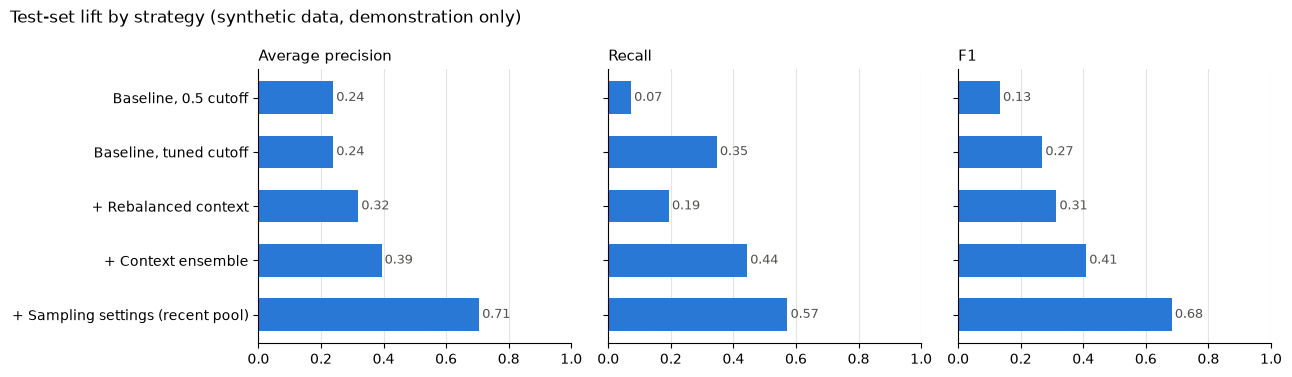

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for axis, (column, title) in zip(axes, [("average_precision", "Average precision"), ("recall", "Recall"), ("f1", "F1")]):
    values = summary[column].to_numpy()[::-1]
    axis.barh(summary.index[::-1], values, color="#2a78d6", height=0.6)
    for position, value in enumerate(values):
        axis.text(value + 0.01, position, f"{value:.2f}", va="center", fontsize=9, color="#52514e")
    axis.set_xlim(0, 1)
    axis.set_title(title, loc="left", fontsize=11)
    axis.spines[["top", "right"]].set_visible(False)
    axis.grid(axis="x", color="#e4e3df", linewidth=0.8)
    axis.set_axisbelow(True)
fig.suptitle("Test-set lift by strategy (synthetic data, demonstration only)", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
plt.show()

## Clean up

Set `CLEANUP = True` to delete this run's directory.

In [18]:
if CLEANUP:
    workspace.cleanup()
print("Removed this run's files." if CLEANUP else f"Results retained in {run_dir}.")